# 1. Build one hourly table and inspect it

**Goal:** put NO2, weather and the calendar into one table with one row per hour, then look at it before deciding how to clean it or which features to build.

Two rules for this notebook:

1. **Change as little as possible.** No value is deleted, filled or capped. Suspicious values are listed, not removed.
2. **Quality checks use every year. Pattern checks use training years only** (2016-2019, 2021-2022). If features were picked because they work in 2024, the 2024 test score would no longer be honest.

Sections 2-5 build the table. Sections 6-8 check its quality. Sections 9-12 look for patterns. D-numbers refer to the decisions in `pipeline_outline.md`.

## 1. Setup

In [1]:
import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.config import CLARK, LOCAL_TZ, PATTERN_YEARS, PROCESSED, RAW, YEARS

no2_files = {y: RAW / "no2" / f"{y}.csv" for y in YEARS}
station_file = RAW / "stations" / "bc_air_monitoring_stations.csv"
weather_files = {y: RAW / "weather_yvr" / f"{y}.csv" for y in YEARS}

needed = list(no2_files.values()) + [station_file] + list(weather_files.values())
missing = [str(f) for f in needed if not f.exists()]
if missing:
    raise FileNotFoundError("run `python download_data.py` first; missing: " + ", ".join(missing))
print("all", len(needed), "input files found")

all 21 input files found


## 2. Load NO2

Each BC row is stamped with the **end** of its hour in fixed PST (UTC-8 all year). We subtract one hour to label it by its **start**, then convert to UTC. UTC has no daylight saving, so every hour exists exactly once.

Rows whose value can't be read as a number are counted and shown, so nothing is lost silently.

In [2]:
parts = []
for y, f in no2_files.items():
    df = pd.read_csv(f, usecols=["DATE_PST", "EMS_ID", "STATION_NAME", "RAW_VALUE", "UNIT", "REGION"], dtype=str, encoding="utf-8")
    df = df[df["REGION"] == "02 - Lower Mainland"].copy()
    df["no2"] = pd.to_numeric(df["RAW_VALUE"], errors="coerce")

    # text that isn't a number (an empty cell is an ordinary gap, not a problem)
    unreadable = df["no2"].isna() & df["RAW_VALUE"].fillna("").str.strip().ne("")
    if unreadable.any():
        print(y, "values that are not numbers:", df.loc[unreadable, "RAW_VALUE"].value_counts().to_dict())

    df["time_utc"] = (pd.to_datetime(df["DATE_PST"]) - pd.Timedelta(hours=1)).dt.tz_localize("Etc/GMT+8").dt.tz_convert("UTC").dt.as_unit("us")
    df["file_year"] = y
    parts.append(df[["EMS_ID", "STATION_NAME", "time_utc", "no2", "UNIT", "file_year"]])

no2_rows = pd.concat(parts, ignore_index=True)
no2_rows["EMS_ID"] = no2_rows["EMS_ID"].str.strip()
print("rows:", len(no2_rows), " rows with a reading:", int(no2_rows["no2"].notna().sum()))
print("units:", no2_rows["UNIT"].unique().tolist())

# two rows for one station and hour would mean two instruments, or overlapping files
readings = no2_rows.dropna(subset=["no2"])
dupes = readings[readings.duplicated(["EMS_ID", "time_utc"], keep=False)]
if len(dupes):
    print(dupes.sort_values(["EMS_ID", "time_utc"]).head(20).to_string())
    raise ValueError(f"{len(dupes)} duplicate readings: decide which to keep before going on")
print("duplicate readings: none")

rows: 2443479  rows with a reading: 2365512
units: ['ppb']
duplicate readings: none


## 3. Stations: IDs, names and locations

A station can be renamed but keep its ID, or be replaced under a new ID. This shows which IDs had which names, and when. It settles the Agassiz question (D4).

`rule_27` is the proposal's rule: a valid daily mean (at least 18 of 24 hours) on at least 75% of days in 2016-2019.

In [3]:
stations = readings.groupby("EMS_ID").agg(
    names=("STATION_NAME", lambda s: " / ".join(s.drop_duplicates())),
    first=("time_utc", "min"),
    last=("time_utc", "max"),
    readings=("no2", "size"),
)
stations["name"] = readings.sort_values("time_utc").groupby("EMS_ID")["STATION_NAME"].last()

coords = pd.read_csv(station_file, dtype={"EMS_ID": str}, encoding="latin-1")
coords["EMS_ID"] = coords["EMS_ID"].str.strip()
coords = coords.drop_duplicates("EMS_ID").set_index("EMS_ID")[["LAT", "LONG"]].astype(float)
stations = stations.join(coords)

# the proposal's 27-station rule
local_day = readings["time_utc"].dt.tz_convert(LOCAL_TZ).dt.date
day_counts = readings.groupby(["EMS_ID", local_day.rename("day")]).size()
good_days = day_counts[day_counts >= 18].reset_index()
in_rule_years = pd.to_datetime(good_days["day"]).dt.year.between(2016, 2019)
stations["rule_27"] = (good_days[in_rule_years].groupby("EMS_ID").size() / 1461 >= 0.75).reindex(stations.index, fill_value=False)

TSA = stations.index[stations["name"] == "Tsawwassen"][0]
TARGETS = {CLARK: "Clark Drive", TSA: "Tsawwassen"}
KEPT = stations.index[stations["rule_27"]].tolist()

print("stations with any reading:", len(stations), " passing the rule:", len(KEPT))
print("IDs with more than one name:", stations.loc[stations["names"].str.contains(" / "), "names"].to_dict() or "none")
print("no coordinates:", stations.loc[stations["LAT"].isna(), "name"].to_dict() or "none")


def km_between(a, b):
    # haversine: shortest distance over the Earth's surface
    la1, lo1 = np.radians(stations.loc[a, ["LAT", "LONG"]].to_numpy(dtype=float))
    la2, lo2 = np.radians(stations.loc[b, ["LAT", "LONG"]].to_numpy(dtype=float))
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))


agassiz = stations.index[stations["names"].str.contains("Agassiz")].tolist()
print("Agassiz IDs:", {i: stations.loc[i, "names"] for i in agassiz})
if len(agassiz) == 2:
    print(f"distance between them: {km_between(*agassiz):.2f} km")

stations.sort_values("name")

stations with any reading: 32  passing the rule: 27
IDs with more than one name: none
no coordinates: none
Agassiz IDs: {'598': 'Agassiz Centennial Park', 'E293810': 'Agassiz Municipal Hall'}
distance between them: 0.90 km


,names,first,last,readings,name,LAT,LONG,rule_27
EMS_ID,,,,,,,,
E289309,Abbotsford A Columbia Street,2015-01-01 08:00:00+00:00,2025-01-01 07:00:00+00:00,85533,Abbotsford A Columbia Street,49.021500,-122.326500,True
E238212,Abbotsford Central,2015-01-01 08:00:00+00:00,2025-01-01 07:00:00+00:00,86330,Abbotsford Central,49.042600,-122.309800,True
598,Agassiz Centennial Park,2024-01-01 08:00:00+00:00,2025-01-01 07:00:00+00:00,8714,Agassiz Centennial Park,49.238360,-121.774780,False
E293810,Agassiz Municipal Hall,2015-01-01 08:00:00+00:00,2024-01-01 07:00:00+00:00,77959,Agassiz Municipal Hall,49.238032,-121.762334,True
0310177,Burnaby Kensington Park,2015-01-01 08:00:00+00:00,2025-01-01 07:00:00+00:00,86000,Burnaby Kensington Park,49.279200,-122.970700,True
E206270,Burnaby Mountain,2015-01-01 08:00:00+00:00,2025-01-01 07:00:00+00:00,86016,Burnaby Mountain,49.279800,-122.922300,True
E207418,Burnaby South,2015-01-02 19:00:00+00:00,2025-01-01 07:00:00+00:00,86295,Burnaby South,49.215200,-122.985700,True
E220891,Chilliwack Airport,2015-01-01 08:00:00+00:00,2025-01-01 07:00:00+00:00,85880,Chilliwack Airport,49.155800,-121.940300,True
E242892,Coquitlam Douglas College,2015-01-01 08:00:00+00:00,2025-01-01 07:00:00+00:00,85140,Coquitlam Douglas College,49.288300,-122.791600,True


## 4. Weather and calendar

Weather is the YVR table made for the proposal. One thing to know: a reading taken at 10:00 is labelled 09:00, to match NO2's start-of-hour label.

The calendar uses **local** time, because traffic follows the clock. Check that the holiday list for 2023 and 2024 includes September 30 (a BC holiday since 2023).

In [4]:
# raw ECCC API output, one file per local year; units converted here as the EDA did
wx = pd.concat((pd.read_csv(f) for f in weather_files.values()), ignore_index=True)
wx["time_utc"] = (pd.to_datetime(wx["UTC_DATE"]).dt.tz_localize("UTC") - pd.Timedelta(hours=1)).dt.as_unit("us") # reading time -> start of hour
wx = wx.rename(columns={"TEMP": "temp", "RELATIVE_HUMIDITY": "rh", "STATION_PRESSURE": "press"})
wx["wspd"] = wx["WIND_SPEED"] / 3.6 # km/h -> m/s
wx["wdir"] = wx["WIND_DIRECTION"] * 10 # tens of degrees -> degrees
wx = wx.set_index("time_utc").sort_index()[["temp", "rh", "wspd", "wdir", "press"]]
print("weather rows:", len(wx), " duplicate hours:", int(wx.index.duplicated().sum()))
assert not wx.index.duplicated().any()

bc_holidays = holidays.Canada(subdiv="BC", years=range(2015, 2026))
for y in (2022, 2023, 2024):
    print(y, sorted(f"{d:%b %d}" for d in bc_holidays if d.year == y))

weather rows: 87608  duplicate hours: 0
2022 ['Apr 15', 'Aug 01', 'Dec 25', 'Dec 26', 'Feb 21', 'Jan 01', 'Jan 03', 'Jul 01', 'May 23', 'Nov 11', 'Oct 10', 'Sep 05', 'Sep 19']
2023 ['Apr 07', 'Aug 07', 'Dec 25', 'Feb 20', 'Jan 01', 'Jan 02', 'Jul 01', 'May 22', 'Nov 11', 'Oct 02', 'Oct 09', 'Sep 04', 'Sep 30']
2024 ['Aug 05', 'Dec 25', 'Feb 19', 'Jan 01', 'Jul 01', 'Mar 29', 'May 20', 'Nov 11', 'Oct 14', 'Sep 02', 'Sep 30']


## 5. One hourly table

The index is every hour of 2015-2024 in fixed PST, stored as UTC: 3,653 days x 24 = 87,672 rows. An hour with no reading is blank. Each NO2 column is named by station ID.

In [5]:
hours = pd.date_range("2015-01-01", "2024-12-31 23:00", freq="h", tz="Etc/GMT+8").tz_convert("UTC").as_unit("us")
hours.name = "time_utc"
assert len(hours) == 87672

no2 = readings.pivot(index="time_utc", columns="EMS_ID", values="no2").reindex(hours)
no2.columns.name = None

local = hours.tz_convert(LOCAL_TZ)
calendar = pd.DataFrame({
    "local_time": local,
    "year": local.year,
    "month": local.month,
    "dow": local.dayofweek, # 0 = Monday
    "hour": local.hour,
    "holiday": [d in bc_holidays for d in local.date],
}, index=hours)
calendar["day_off"] = calendar["holiday"] | (calendar["dow"] >= 5)

grid = pd.concat([calendar, wx.reindex(hours), no2.add_prefix("no2_")], axis=1)

# nothing may be lost or invented on the way into the table
assert int(no2.notna().sum().sum()) == len(readings)
print("table:", grid.shape, " NO2 readings in:", len(readings), " out:", int(no2.notna().sum().sum()))
print("hours with no weather at all:", int(wx.reindex(hours).isna().all(axis=1).sum()))
grid.iloc[4000:4005, :14]

table: (87672, 44)  NO2 readings in: 2365512  out: 2365512
hours with no weather at all: 65


/var/folders/_q/s87t6qn535vgg6bjlc68qzwr0000gn/T/ipykernel_54408/1023370668.py:13: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "dow": local.dayofweek, # 0 = Monday


,local_time,year,month,dow,hour,holiday,day_off,temp,rh,wspd,wdir,press,no2_0220204,no2_0220205
time_utc,,,,,,,,,,,,,,
2015-06-17 00:00:00+00:00,2015-06-16 17:00:00-07:00,2015,6,1,17,False,False,21.3,43.0,4.444444,130.0,101.58,3.105222,NaN
2015-06-17 01:00:00+00:00,2015-06-16 18:00:00-07:00,2015,6,1,18,False,False,20.0,48.0,3.888889,130.0,101.55,5.937116,NaN
2015-06-17 02:00:00+00:00,2015-06-16 19:00:00-07:00,2015,6,1,19,False,False,18.0,54.0,4.722222,120.0,101.55,3.013580,NaN
2015-06-17 03:00:00+00:00,2015-06-16 20:00:00-07:00,2015,6,1,20,False,False,16.5,59.0,4.444444,130.0,101.57,3.936866,NaN
2015-06-17 04:00:00+00:00,2015-06-16 21:00:00-07:00,2015,6,1,21,False,False,15.4,62.0,6.111111,130.0,101.60,NaN,NaN


## 6. Do the sources line up?

**Why:** a one-hour mistake in time conversion won't raise an error. It just quietly weakens every feature.

**How to read it:**
- Left: the weekday morning peak should fall at the **same local hour** in winter and summer. If the summer curve sits one hour off, the daylight saving conversion is wrong.
- Right: temperature should be lowest near sunrise and highest in mid-afternoon.

busiest morning hour, 4-12 local: {'summer': 8, 'winter': 8}


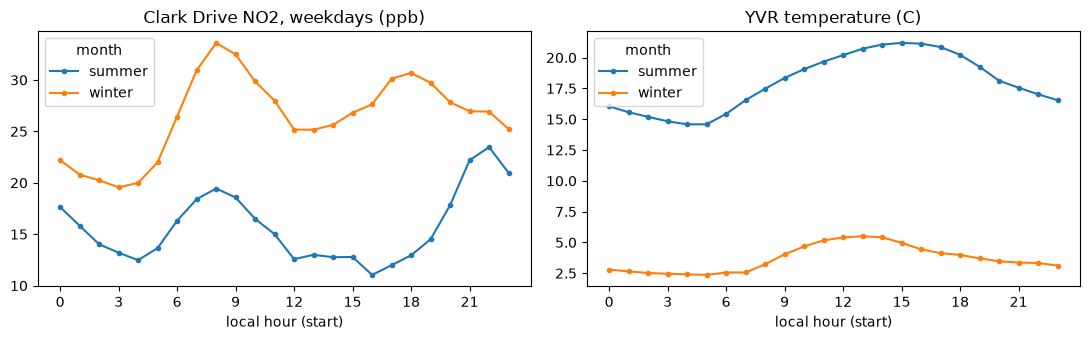

In [6]:
clark = no2[CLARK]
season = calendar["month"].map({12: "winter", 1: "winter", 2: "winter", 6: "summer", 7: "summer", 8: "summer"})
weekday_train = ~calendar["day_off"] & calendar["year"].isin(PATTERN_YEARS)

peak = clark[weekday_train].groupby([calendar["hour"], season]).mean().unstack()
temp_by_hour = grid.loc[weekday_train, "temp"].groupby([calendar["hour"], season]).mean().unstack()
print("busiest morning hour, 4-12 local:", peak.loc[4:12].idxmax().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
peak.plot(ax=axes[0], marker="o", ms=3, title="Clark Drive NO2, weekdays (ppb)")
temp_by_hour.plot(ax=axes[1], marker="o", ms=3, title="YVR temperature (C)")
for ax in axes:
    ax.set_xlabel("local hour (start)")
    ax.set_xticks(range(0, 24, 3))
plt.tight_layout()
plt.show()

## 7. Coverage and gaps (D4, D6)

**Coverage:** percent of hours with a reading. Look for pale cells in 2023 and 2024, which are the tune and test years.

**Gaps:** the proposal fills gaps of up to 3 hours for the graph model. The table shows how many missing hours that actually covers. The plot shows whether gaps cluster at certain hours, for example a daily calibration.

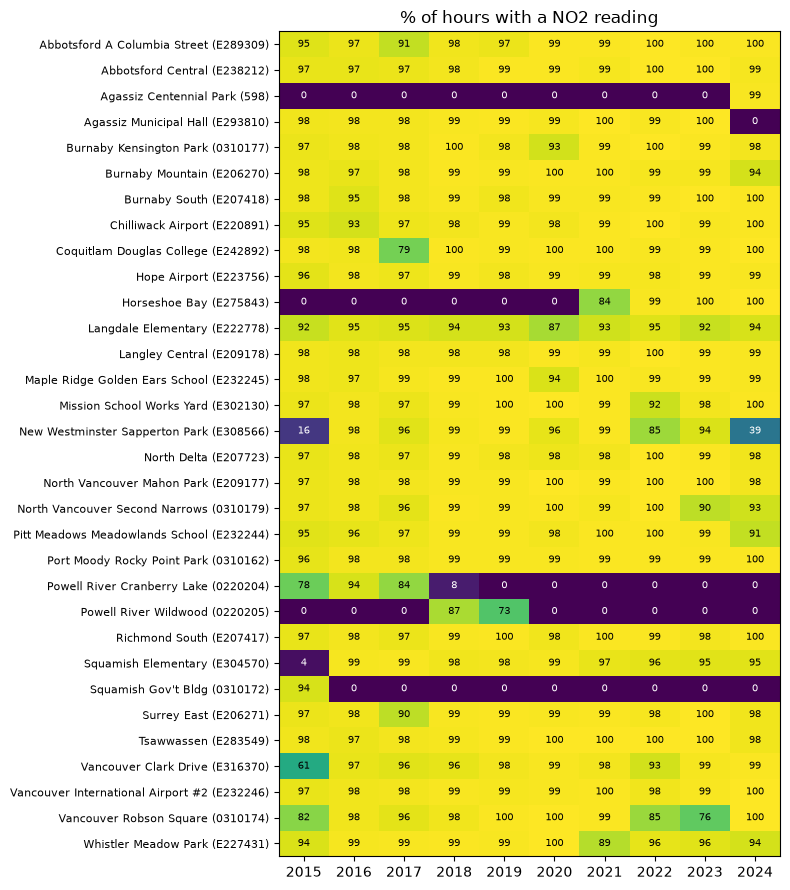

kept stations below 90% in some year, 2016-2024
year                            2016  2017   2018   2019   2020   2021  2022   2023   2024
name                                                                                      
Vancouver Robson Square         98.0  96.0   98.0  100.0  100.0   99.0  85.0   76.0  100.0
Surrey East                     98.0  90.0   99.0   99.0   99.0   99.0  98.0  100.0   98.0
Langdale Elementary             95.0  95.0   94.0   93.0   87.0   93.0  95.0   92.0   94.0
Whistler Meadow Park            99.0  99.0   99.0   99.0  100.0   89.0  96.0   96.0   94.0
Coquitlam Douglas College       98.0  79.0  100.0   99.0  100.0  100.0  99.0   99.0  100.0
Agassiz Municipal Hall          98.0  98.0   99.0   99.0   99.0  100.0  99.0  100.0    0.0
New Westminster Sapperton Park  98.0  96.0   99.0   99.0   96.0   99.0  85.0   94.0   39.0


In [7]:
coverage = no2.notna().groupby(calendar["year"]).mean().T * 100
coverage.index = [f"{stations.loc[i, 'name']} ({i})" for i in coverage.index]
coverage = coverage[YEARS].sort_index()

fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(coverage, aspect="auto", cmap="viridis", vmin=0, vmax=100)
ax.set_xticks(range(len(YEARS)), YEARS)
ax.set_yticks(range(len(coverage)), coverage.index, fontsize=8)
for r in range(len(coverage)):
    for c in range(len(YEARS)):
        v = coverage.iloc[r, c]
        ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v < 60 else "black")
ax.set_title("% of hours with a NO2 reading")
plt.tight_layout()
plt.show()

kept_cov = no2[KEPT].notna().groupby(calendar["year"]).mean().T.loc[:, 2016:2024] * 100
weak = kept_cov[kept_cov.min(axis=1) < 90].round(0)
weak.index = stations.loc[weak.index, "name"]
print("kept stations below 90% in some year, 2016-2024")
print(weak.to_string())

gaps between each kept station's first and last reading
              gaps  missing_hours  % of missing hours
hours                                                
1 h          18299          18299                30.0
2-3 h         1784           4191                 6.9
4-6 h          629           2983                 4.9
7-24 h         371           4522                 7.4
1-7 days       167          10217                16.7
over 7 days     27          20826                34.1

longest gaps
                           name                     start  hours
 New Westminster Sapperton Park 2024-05-02 17:00:00+00:00   5357
        Vancouver Robson Square 2022-11-17 08:00:00+00:00   3013
      Coquitlam Douglas College 2017-06-20 14:00:00+00:00   1688
 North Vancouver Second Narrows 2023-11-27 19:00:00+00:00   1417
 New Westminster Sapperton Park 2022-06-20 16:00:00+00:00    941
Pitt Meadows Meadowlands School 2024-03-01 08:00:00+00:00    744
                    Surrey East 2017-07-12 

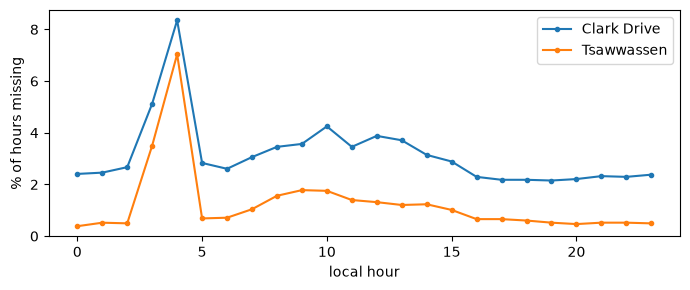

In [8]:
def runs_of(flag):
    # consecutive True values: start time, length in hours
    run_id = (flag != flag.shift()).cumsum()
    on = flag[flag]
    if on.empty:
        return pd.DataFrame(columns=["start", "hours"])
    g = on.index.to_series().groupby(run_id[flag])
    return pd.DataFrame({"start": g.first(), "hours": g.size()}).reset_index(drop=True)


rows = []
for i in KEPT:
    s = no2[i].loc[no2[i].first_valid_index():no2[i].last_valid_index()]
    r = runs_of(s.isna())
    r["station"] = i
    rows.append(r)
gaps = pd.concat(rows, ignore_index=True)

bands = pd.cut(gaps["hours"], [0, 1, 3, 6, 24, 168, np.inf], labels=["1 h", "2-3 h", "4-6 h", "7-24 h", "1-7 days", "over 7 days"])
summary = gaps.groupby(bands, observed=False)["hours"].agg(gaps="size", missing_hours="sum")
summary["% of missing hours"] = (summary["missing_hours"] / summary["missing_hours"].sum() * 100).round(1)
print("gaps between each kept station's first and last reading")
print(summary.to_string())
print()
print("longest gaps")
longest = gaps.nlargest(10, "hours").assign(name=lambda d: stations.loc[d["station"], "name"].to_numpy())
print(longest[["name", "start", "hours"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
for i, name in TARGETS.items():
    s = no2[i].loc[no2[i].first_valid_index():no2[i].last_valid_index()]
    (s.isna().groupby(calendar["hour"].reindex(s.index)).mean() * 100).plot(ax=ax, marker="o", ms=3, label=name)
ax.set_ylabel("% of hours missing")
ax.set_xlabel("local hour")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Suspicious values (D8)

Nothing is removed here. Three lists:

- **Negative:** impossible as a concentration. The proposal treats these as missing.
- **Stuck:** the same value 6 or more hours in a row. Zeros are counted separately, because a clean site can genuinely read 0.
- **Spike:** a single hour far above the median of the 25 hours around it. The gap is measured in MADs (median absolute deviation, a spread measure that extremes can't distort). The cut-off of 10 only decides what to **look at**. Real pollution episodes usually last several hours and show up at nearby stations too.

`look(station, time)` plots the surrounding days, with the nearest stations for comparison.

negatives: 116 over all stations (proposal says 116), 48 in kept stations, lowest -0.0 ppb
stuck runs: 1 non-zero, 0 at zero
lone spikes: 3256

longest non-zero stuck runs
station                     start  hours  value                name
E222778 2021-10-02 05:00:00+00:00     10    2.0 Langdale Elementary

largest spikes
station                      time      no2     score                            name
E222778 2021-10-10 13:00:00+00:00 22.91731 43.971542             Langdale Elementary
E232244 2020-01-20 15:00:00+00:00 20.97667 39.665007 Pitt Meadows Meadowlands School
E222778 2015-02-22 19:00:00+00:00 20.81894 34.598118             Langdale Elementary
E222778 2023-09-09 01:00:00+00:00 21.93980 33.467540             Langdale Elementary
E222778 2021-04-17 01:00:00+00:00 30.91667 32.725178             Langdale Elementary
E232244 2023-10-25 16:00:00+00:00 18.90043 31.973642 Pitt Meadows Meadowlands School
E222778 2017-05-29 02:00:00+00:00 28.33417 30.700337             Langdale Element

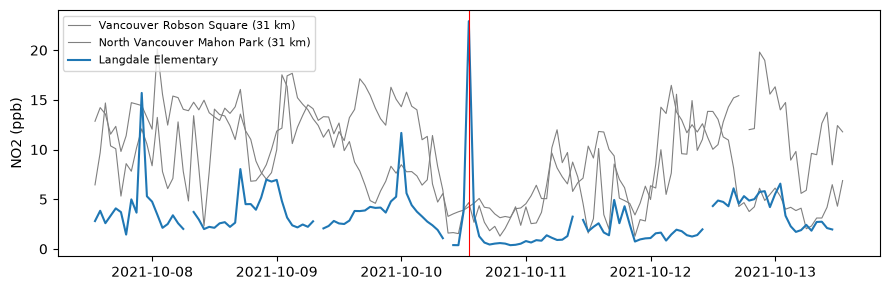

In [9]:
neg_rows, stuck_rows, spike_rows = [], [], []
for i in KEPT:
    s = no2[i]
    for t, v in s[s < 0].items():
        neg_rows.append((i, t, v))

    same = s.eq(s.shift()) & s.notna()
    r = runs_of(same)
    for _, x in r[r["hours"] >= 5].iterrows(): # 5 repeats = 6 equal hours
        stuck_rows.append((i, x["start"] - pd.Timedelta(hours=1), x["hours"] + 1, s[x["start"]]))

    med = s.rolling(25, center=True, min_periods=13).median()
    mad = (s - med).abs().rolling(25, center=True, min_periods=13).median()
    score = (s - med) / mad.clip(lower=0.5) # floor, so a flat stretch doesn't make tiny wiggles look huge
    lone = (score > 10) & ~(score.shift(1) > 10) & ~(score.shift(-1) > 10)
    for t in s.index[lone]:
        spike_rows.append((i, t, s[t], score[t]))

negatives = pd.DataFrame(neg_rows, columns=["station", "time", "no2"])
stuck = pd.DataFrame(stuck_rows, columns=["station", "start", "hours", "value"])
spikes = pd.DataFrame(spike_rows, columns=["station", "time", "no2", "score"])

all_neg = int((no2 < 0).sum().sum())
print(f"negatives: {all_neg} over all stations (proposal says 116), {len(negatives)} in kept stations, lowest {no2.min().min():.1f} ppb")
print(f"stuck runs: {int((stuck['value'] != 0).sum())} non-zero, {int((stuck['value'] == 0).sum())} at zero")
print(f"lone spikes: {len(spikes)}")

for label, t in [("longest non-zero stuck runs", stuck[stuck["value"] != 0].nlargest(8, "hours")), ("largest spikes", spikes.nlargest(8, "score"))]:
    print()
    print(label)
    print(t.assign(name=stations.loc[t["station"], "name"].to_numpy()).to_string(index=False))


def look(station, time, days=3, n_near=2):
    near = sorted((i for i in KEPT if i != station), key=lambda i: km_between(station, i))[:n_near]
    window = slice(time - pd.Timedelta(days=days), time + pd.Timedelta(days=days))
    fig, ax = plt.subplots(figsize=(9, 3))
    for i in near:
        ax.plot(no2.loc[window, i], color="grey", lw=0.8, label=f"{stations.loc[i, 'name']} ({km_between(station, i):.0f} km)")
    ax.plot(no2.loc[window, station], lw=1.5, label=stations.loc[station, "name"])
    ax.axvline(time, color="red", lw=0.8)
    ax.set_ylabel("NO2 (ppb)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


if len(spikes):
    x = spikes.loc[spikes["score"].idxmax()]
    look(x["station"], x["time"])

## 9. How well does NO2 predict itself? (D2)

**Training years only from here on.**

Two curves per station:
- **Raw:** correlation between an hour and the hour k hours earlier. The daily cycle inflates it: 8 am today resembles 8 am yesterday partly because both are rush hour.
- **Beyond the usual:** the same after subtracting the average for that month, day type (working day or day off) and hour. This is what recent NO2 tells you that the **calendar doesn't already**.

Reading k: the last hour known at forecast time is exactly h hours before the target that is h hours ahead. So **k = hours ahead** for the most recent reading.

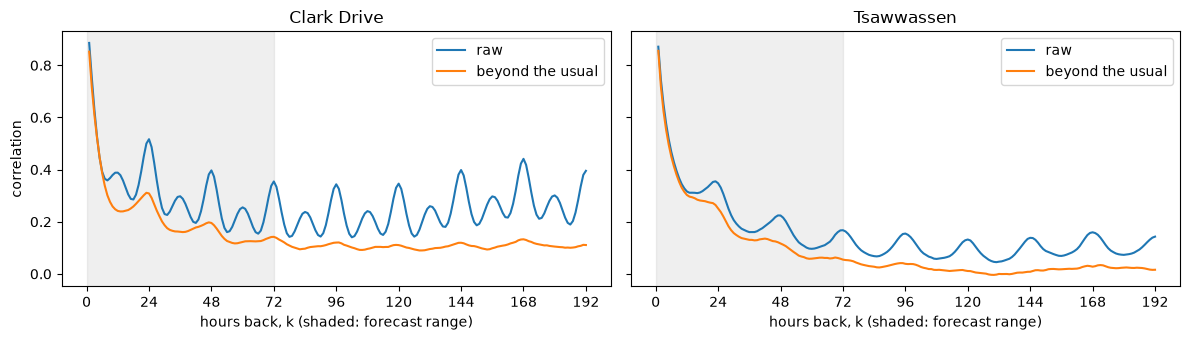

    Clark Drive                  Tsawwassen                 
            raw beyond the usual        raw beyond the usual
1          0.89             0.85       0.87             0.86
3          0.63             0.61       0.65             0.62
6          0.39             0.39       0.47             0.45
12         0.39             0.24       0.32             0.30
24         0.52             0.31       0.35             0.25
48         0.40             0.20       0.22             0.12
72         0.35             0.14       0.17             0.05
168        0.44             0.13       0.16             0.03


In [10]:
in_pattern = calendar["year"].isin(PATTERN_YEARS)
usual_groups = [calendar["month"], calendar["day_off"], calendar["hour"]] # what the calendar features already tell a model

no2_train = no2[KEPT].where(in_pattern)
usual = no2_train.groupby(usual_groups).transform("mean")
anomaly = no2_train - usual

lags = range(1, 193)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
self_corr = {}
for ax, (i, name) in zip(axes, TARGETS.items()):
    self_corr[name] = pd.DataFrame({
        "raw": [no2_train[i].corr(no2_train[i].shift(k)) for k in lags],
        "beyond the usual": [anomaly[i].corr(anomaly[i].shift(k)) for k in lags],
    }, index=lags)
    self_corr[name].plot(ax=ax, title=name)
    ax.axvspan(0, 72, color="grey", alpha=0.12)
    ax.set_xticks(range(0, 193, 24))
    ax.set_xlabel("hours back, k (shaded: forecast range)")
axes[0].set_ylabel("correlation")
plt.tight_layout()
plt.show()

print(pd.concat({n: d.loc[[1, 3, 6, 12, 24, 48, 72, 168]] for n, d in self_corr.items()}, axis=1).round(2).to_string())

## 10. How long does weather stay useful? (D3)

Correlation between NO2 (beyond the usual) and the weather k hours **earlier**. We have no weather forecasts, so the value at k = 24 is how useful today's observation still is for a target a day ahead.

A curve that drops to about 0 within a few hours can only help the first hours of the forecast. Wind is split into u (positive: air moving east) and v (positive: air moving north). Calm hours become (0, 0).

k = 0 is drawn for reference only. A forecast can't use it.

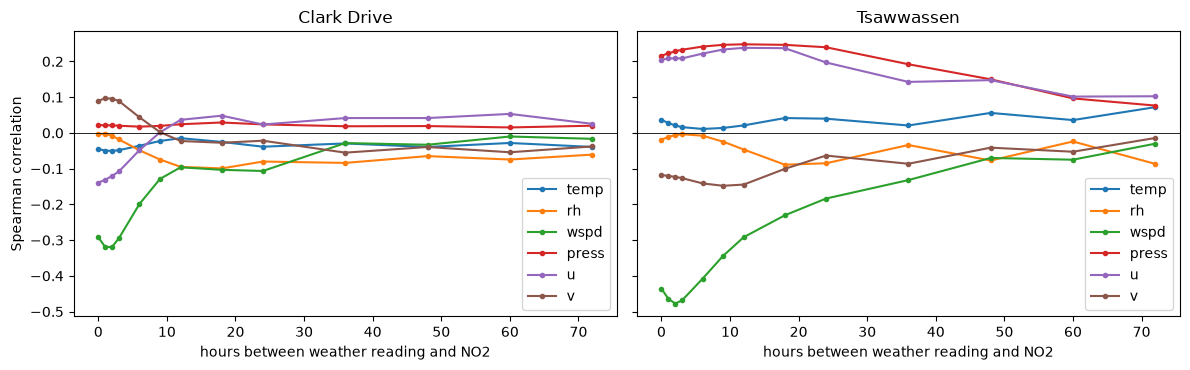

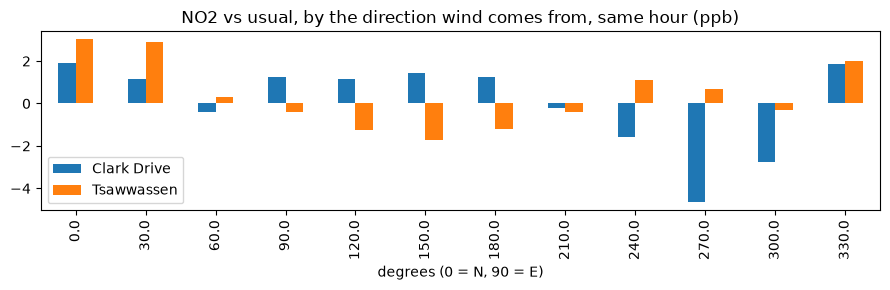

In [11]:
rad = np.radians(grid["wdir"])
wind = pd.DataFrame({"u": -grid["wspd"] * np.sin(rad), "v": -grid["wspd"] * np.cos(rad)}, index=grid.index)
wind[grid["wspd"] == 0] = 0.0
weather = pd.concat([grid[["temp", "rh", "wspd", "press"]], wind], axis=1).where(in_pattern)

steps = [0, 1, 2, 3, 6, 9, 12, 18, 24, 36, 48, 60, 72]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
weather_corr = {}
for ax, (i, name) in zip(axes, TARGETS.items()):
    weather_corr[name] = pd.DataFrame({c: [anomaly[i].corr(weather[c].shift(k), method="spearman") for k in steps] for c in weather}, index=steps)
    weather_corr[name].plot(ax=ax, marker="o", ms=3, title=name)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xlabel("hours between weather reading and NO2")
axes[0].set_ylabel("Spearman correlation")
plt.tight_layout()
plt.show()

sector = ((grid["wdir"] / 30).round() % 12 * 30).where((grid["wspd"] > 0) & in_pattern)
by_dir = pd.DataFrame({name: anomaly[i].groupby(sector).mean() for i, name in TARGETS.items()})
by_dir.plot(kind="bar", figsize=(9, 3), title="NO2 vs usual, by the direction wind comes from, same hour (ppb)")
plt.xlabel("degrees (0 = N, 90 = E)")
plt.tight_layout()
plt.show()

## 11. Which neighbours add something new? (D5)

A neighbour that rises **together with** the target is not enough. The question is whether the neighbour's reading k hours ago says anything **beyond the target's own reading** k hours ago.

That is a **partial correlation**: the link between the neighbour and the target after removing what the target's own value already explains. Near 0 means it adds nothing. The sign can be negative.

These are small numbers by nature, and with 26 neighbours some will look good by luck. Look for neighbours that stay consistent across columns.

In [12]:
def partial_corr(x, y, z):
    r = pd.DataFrame({"x": x, "y": y, "z": z}).dropna().corr()
    return (r.loc["x", "y"] - r.loc["x", "z"] * r.loc["y", "z"]) / np.sqrt((1 - r.loc["x", "z"] ** 2) * (1 - r.loc["y", "z"] ** 2))


neighbour_tables = {}
for target, name in TARGETS.items():
    rows = {}
    for j in KEPT:
        if j == target:
            continue
        row = {"km": km_between(target, j), "same hour (plain)": anomaly[target].corr(anomaly[j])}
        for k in [1, 3, 6, 12, 24]:
            row[f"adds, {k} h ahead"] = partial_corr(anomaly[j].shift(k), anomaly[target], anomaly[target].shift(k))
        rows[stations.loc[j, "name"]] = row
    neighbour_tables[name] = pd.DataFrame(rows).T.sort_values("km")
    print(name)
    print(neighbour_tables[name].round(2).to_string())
    print()

Clark Drive
                                        km  same hour (plain)  adds, 1 h ahead  adds, 3 h ahead  adds, 6 h ahead  adds, 12 h ahead  adds, 24 h ahead
Vancouver Robson Square               4.03               0.68             0.10             0.08             0.06              0.05              0.01
North Vancouver Second Narrows        6.19               0.23             0.11             0.14             0.14              0.13              0.06
North Vancouver Mahon Park            7.10               0.51             0.11             0.11             0.09              0.11              0.08
Burnaby Kensington Park               8.05               0.45             0.12             0.12             0.14              0.15              0.08
Burnaby South                         8.36               0.55             0.08             0.09             0.11              0.12              0.05
Vancouver International Airport #2    9.85               0.57             0.15             0.1

## 12. Is NO2 drifting over the years?

Training years only, so this doesn't peek at 2023-2024. A steady fall means a model trained on older years may predict too high in 2024. Features describing the **recent level** help with that.

      Clark Drive  Tsawwassen
year                         
2016         20.8         6.3
2017         22.1         7.1
2018         19.2         6.6
2019         17.9         6.7
2021         16.4         5.4
2022         16.0         5.9


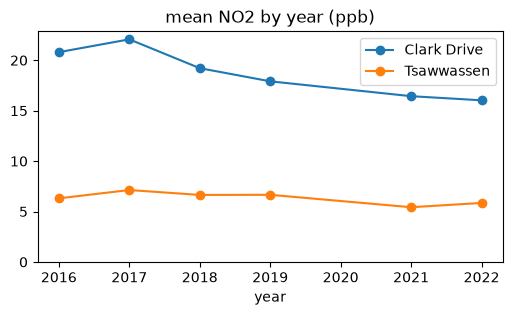

In [13]:
yearly = pd.DataFrame({name: no2_train[i].groupby(calendar["year"]).mean() for i, name in TARGETS.items()}).dropna()
print(yearly.round(1).to_string())
yearly.plot(marker="o", figsize=(6, 3), title="mean NO2 by year (ppb)")
plt.ylim(bottom=0)
plt.show()

## 13. Save the table

Untouched values: no cleaning has been applied. Reading it back checks that the file matches what's in memory.

In [14]:
out = PROCESSED / "hourly_grid.parquet"
grid.to_parquet(out)
check = pd.read_parquet(out)
pd.testing.assert_frame_equal(check, grid, check_freq=False)
print("saved", out, grid.shape)

saved /Users/royguo/Desktop/bcit_msc/comp9170/ProjGroup7/data/processed/hourly_grid.parquet (87672, 44)
